# RAG Assignment: Baseline (Bi-Encoder) vs. Re-Ranking (Cross-Encoder)

**Document:** Regulation (EU) 2016/679 - the *General Data Protection Regulation* (GDPR), official EUR-Lex PDF, 88 pages.
It is a good stress test for retrieval because it

* has **two layers of text that talk about the same topics**: 173 *recitals* (explanatory, non-binding prose) and 99 *articles* (the binding rules). Recitals make perfect distractors.
* is full of **exceptions** ("Paragraph 1 shall not apply if ..."), **negations** ("shall not be dismissed or penalised") and **cross references** ("referred to in Article 9(1)").
* uses **formal legal vocabulary** ("erasure", "administrative fine", "manifestly unfounded or excessive") while users ask in everyday words ("delete", "penalty", "ignore").

**Pipelines compared over the exact same chunk corpus**

| | Pipeline 1 - Baseline | Pipeline 2 - Re-ranking |
|---|---|---|
| Stage 1 | Bi-encoder `all-MiniLM-L6-v2`, cosine similarity, Top-10 | *same Top-10 candidates* |
| Stage 2 | take Top-3 as-is | Cross-encoder `ms-marco-MiniLM-L-6-v2` scores all 10 (query, chunk) pairs, re-sort, take Top-3 |
| Generation | identical prompt + LLM -> **Answer 1** | identical prompt + LLM -> **Answer 2** |

Notebook outline: 1 Setup -> 2 Load PDF -> 3 Chunking -> 4 Index -> 5 Pipelines -> 6 LLM -> 7 Failure-mode analysis -> 8 Quantitative evaluation -> 9 Latency -> 10 Scaling experiment.

## 1. Setup & configuration

In [1]:
# All configuration lives in this one cell so every experiment below is reproducible.
import os, re, time, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pypdf
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, CrossEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())

PDF_PATH        = Path("data/gdpr.pdf")      # https://eur-lex.europa.eu/legal-content/EN/TXT/PDF/?uri=CELEX:32016R0679
BI_ENCODER      = "sentence-transformers/all-MiniLM-L6-v2"     # 22M params, 384-dim, max 256 word-pieces
CROSS_ENCODER   = "cross-encoder/ms-marco-MiniLM-L-6-v2"       # 22M params, trained on MS MARCO passage ranking
LOCAL_LLM_PATH  = Path("models/Qwen2.5-0.5B-Instruct")         # local copy; falls back to the HF hub id below
LOCAL_LLM_ID    = "Qwen/Qwen2.5-0.5B-Instruct"
GEMINI_MODEL    = "gemini-2.5-flash"                           # used instead of the local model if GEMINI_API_KEY is set

TOP_K_RETRIEVE  = 10    # candidates from the bi-encoder (assignment spec)
TOP_N_CONTEXT   = 3     # chunks given to the LLM (assignment spec)
MAX_CHUNK_WORDS = 150   # see chunking section for why

RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)
print("torch", torch.__version__, "| threads", torch.get_num_threads(), "| device: cpu")

C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.0+cpu | threads 20 | device: cpu


## 2. Load and clean the PDF

`pypdf` extracts the text page by page. Two kinds of noise must be removed before chunking, otherwise they end up inside the embeddings:

1. **Running headers** on every page (`4.5.2016 L 119/32 Official Journal of the European Union EN`).
2. **Page-bottom footnotes** (`(1) OJ L 281, 23.11.1995, p. 31.`). They are printed in the *middle* of the extracted text whenever a recital or article continues onto the next page, so they would split one paragraph into two unrelated pieces. They also look like recital numbers `(1)`, which would break the recital splitter.

In [2]:
HEADER_LINE = re.compile(r"^.*(Official Journal of the European Union|L\s*119/\d+).*$", re.M)
# A footnote never crosses a new "(n)" line, which stops the non-greedy match from eating a real recital.
FOOTNOTES = [
    re.compile(r"\n\(\d\) OJ [LC] [^\n]*"),
    re.compile(r"\n\(\d\) (?:(?!\n\(\d)[\s\S]){0,900}?\(OJ [LC] [^)]*\)\.?[ ]*(?=\n)"),
    re.compile(r"\n\(\d\) Position of the European Parliament[\s\S]*?Parliament of 14 April 2016\.?[ ]*(?=\n)"),
]

def load_pdf_text(path):
    reader = pypdf.PdfReader(path)
    pages = [p.extract_text() or "" for p in reader.pages]
    text = "\n".join(HEADER_LINE.sub("", p) for p in pages)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n\s*EN\s*\n", "\n", text)
    n_footnotes = sum(len(p.findall(text)) for p in FOOTNOTES)
    for p in FOOTNOTES:
        text = p.sub("", text)
    return text, len(pages), n_footnotes

raw_text, n_pages, n_footnotes = load_pdf_text(PDF_PATH)
print(f"pages: {n_pages} | characters after cleaning: {len(raw_text):,} | footnotes removed: {n_footnotes}")

pages: 88 | characters after cleaning: 349,776 | footnotes removed: 20


## 3. Chunking - structure-aware, paragraph level

**Design choices**

* **Follow the legal structure instead of fixed-size windows.** The regulation is split into *recitals* `(1)...(173)` and *articles* `Article 1 ... Article 99`. Articles are further split on their numbered paragraphs (`1.`, `2.`, ...). A fixed 500-character window would cut a rule in half (e.g. separate "Paragraph 1 shall not apply" from the list of exceptions that follows it).
* **Max ~150 words per chunk.** `all-MiniLM-L6-v2` truncates input at 256 word-pieces; legal English is ~1.4-1.6 word-pieces per word, so 150 words fits without silent truncation. Small chunks also make the retrieval failures *visible*: the general rule and its exception usually land in **different** chunks, which is exactly the "except when..." scenario the assignment asks about.
* **Greedy packing.** Consecutive short paragraphs of the same article are packed together up to the limit; a paragraph longer than the limit is split on sentence/clause boundaries (`.`, `;`, `:`), and fragments under 30 words are merged back so no chunk is a meaningless tail like "or (e) ...".
* **Article header prefix.** Every article chunk starts with `Article N - Title:`. A middle paragraph such as "3. Paragraphs 1 and 2 shall not apply..." says nothing about *what* it is an exception to; the prefix restores that context for both encoders. Recital chunks keep their `(n)` number.
* **No overlap.** Paragraph boundaries are natural semantic boundaries in legislation, so overlap mostly adds duplicates that would compete for the same Top-3 slots.

In [3]:
def clean(s):
    s = s.replace("\xad\n", "").replace("\xad", "")    # soft hyphens from the OJ typesetting
    s = re.sub(r"-\n(?=[a-z])", "", s)                 # re-join words hyphenated at a line break
    s = re.sub(r"\s*\n\s*", " ", s)                    # flatten soft line breaks
    return re.sub(r"\s{2,}", " ", s).strip()

def pack(units, max_words):
    # Greedily pack consecutive paragraphs into chunks of <= max_words words.
    out, cur = [], []
    for u in units:
        if len(u.split()) > max_words:                 # one paragraph is too long -> split on clauses
            if cur: out.append(" ".join(cur)); cur = []
            buf = []
            for s in re.split(r"(?<=[.;:])\s+", u):
                if buf and len(" ".join(buf + [s]).split()) > max_words:
                    out.append(" ".join(buf)); buf = []
                buf.append(s)
            if buf: out.append(" ".join(buf))
            continue
        if cur and len(" ".join(cur + [u]).split()) > max_words:
            out.append(" ".join(cur)); cur = []
        cur.append(u)
    if cur: out.append(" ".join(cur))
    merged = []                                        # glue tiny tails back onto the previous chunk
    for piece in out:
        if merged and len(piece.split()) < 30: merged[-1] += " " + piece
        else: merged.append(piece)
    return merged

def chunk_gdpr(text, max_words=MAX_CHUNK_WORDS):
    cut = text.find("HAVE ADOPTED THIS REGULATION")
    recital_part, article_part = text[:cut], text[cut:]
    chunks = []
    # Recitals: "(1) ...", "(2) ..." -> one chunk each (split if long)
    for block in re.split(r"\n\s*(?=\(\d{1,3}\)\s)", recital_part):
        m = re.match(r"\((\d{1,3})\)\s", block)
        if not m: continue
        body = clean(block)
        if len(body.split()) < 15: continue
        for i, piece in enumerate(pack([body], max_words)):
            chunks.append({"source": f"Recital {m.group(1)}", "kind": "recital",
                           "text": piece if i == 0 else f"(Recital {m.group(1)}, cont.) {piece}"})
    # Articles: "Article N\nTitle\n1. ...\n2. ..." -> paragraph-level chunks with an article header
    for art in re.split(r"\n\s*(?=Article\s+\d+\s*\n)", article_part):
        m = re.match(r"Article\s+(\d+)\s*\n(.*?)\n", art)
        if not m: continue
        num, title = m.group(1), clean(m.group(2))
        body = re.split(r"\n\s*(CHAPTER [IVXL]+|Section \d+)\s*\n", art[m.end():])[0]   # drop next chapter heading
        paras = [clean(p) for p in re.split(r"\n\s*(?=\d{1,2}\.\s)", body) if clean(p)]
        for piece in pack(paras, max_words):
            chunks.append({"source": f"Article {num}", "kind": "article", "text": f"Article {num} - {title}: {piece}"})
    for i, c in enumerate(chunks):
        c["id"] = i
    return chunks

chunks = chunk_gdpr(raw_text)
df_chunks = pd.DataFrame(chunks)
df_chunks["words"] = df_chunks.text.str.split().str.len()
print(f"{len(chunks)} chunks | recitals covered: {df_chunks[df_chunks.kind=='recital'].source.nunique()} / 173 "
      f"| articles covered: {df_chunks[df_chunks.kind=='article'].source.nunique()} / 99")
display(df_chunks.groupby("kind").words.describe().round(1))
df_chunks.to_csv(RESULTS / "chunks.csv", index=False)

523 chunks | recitals covered: 173 / 173 | articles covered: 99 / 99


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
article,280.0,113.3,35.7,32.0,83.0,125.0,143.0,184.0
recital,243.0,98.4,38.3,23.0,67.0,104.0,130.0,237.0


In [4]:
# Example: Article 17 (right to erasure) - the general rule (para 1) and the exceptions (para 3) are separate chunks.
for c in chunks:
    if c["source"] == "Article 17":
        print(f"[chunk {c['id']}] {c['text'][:230]}...\n")

[chunk 300] Article 17 - Right to erasure (‘right to be forgotten’): 1. The data subject shall have the right to obtain from the controller the erasure of personal data concerning him or her without undue delay and the controller shall have t...

[chunk 301] Article 17 - Right to erasure (‘right to be forgotten’): (e) the personal data have to be erased for compliance with a legal obligation in Union or Member State law to which the controller is subject; (f) the personal data have be...

[chunk 302] Article 17 - Right to erasure (‘right to be forgotten’): 2. Where the controller has made the personal data public and is obliged pursuant to paragraph 1 to erase the personal data, the controller, taking account of available tech...

[chunk 303] Article 17 - Right to erasure (‘right to be forgotten’): 3. Paragraphs 1 and 2 shall not apply to the extent that processing is necessary: (a) for exercising the right of freedom of expression and information; (b) for compliance w...



## 4. Models and the vector index

* **Bi-encoder** `all-MiniLM-L6-v2`: query and chunk are encoded *independently* into 384-dim vectors; relevance = cosine similarity. Chunk vectors are computed once, offline.
* **Vector store**: with 523 chunks the "store" is a `523 x 384` matrix of L2-normalised float32 vectors. Search is an exact matrix-vector product (`emb @ q`), which for unit vectors equals cosine similarity and gives identical results to `faiss.IndexFlatIP`. An approximate index (HNSW/IVF) would only matter at ~10^5+ chunks and would add approximation error to the comparison.
* **Cross-encoder** `ms-marco-MiniLM-L-6-v2`: reads `[CLS] query [SEP] chunk [SEP]` as one sequence and outputs one relevance logit. Same 6-layer MiniLM size as the bi-encoder, so the comparison isolates the *architecture* (independent vs joint encoding) rather than model size.

In [5]:
t0 = time.perf_counter()
bi_encoder = SentenceTransformer(BI_ENCODER, device="cpu")
cross_encoder = CrossEncoder(CROSS_ENCODER, device="cpu")
print(f"models loaded in {time.perf_counter()-t0:.1f}s | bi-encoder max_seq_length = {bi_encoder.max_seq_length}")

# How many chunks would be truncated by the bi-encoder's 256 word-piece limit?
n_tok = [len(bi_encoder.tokenizer(c["text"])["input_ids"]) for c in chunks]
print(f"word-pieces per chunk: median {int(np.median(n_tok))}, max {max(n_tok)}, chunks longer than 256 (tail truncated): {sum(t > 256 for t in n_tok)}")

t0 = time.perf_counter()
chunk_emb = bi_encoder.encode([c["text"] for c in chunks], batch_size=32, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False).astype("float32")
index_time = time.perf_counter() - t0
print(f"indexed {chunk_emb.shape[0]} chunks -> matrix {chunk_emb.shape} in {index_time:.2f}s (one-off, offline cost)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12909.02it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 4600.41it/s]


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (270 > 256). Running this sequence through the model will result in indexing errors


models loaded in 0.9s | bi-encoder max_seq_length = 256


word-pieces per chunk: median 132, max 270, chunks longer than 256 (tail truncated): 1


indexed 523 chunks -> matrix (523, 384) in 7.66s (one-off, offline cost)


## 5. The two retrieval pipelines

Both pipelines share `dense_search` (stage 1). Pipeline 2 only adds `rerank` on the **same** 10 candidates, so any difference in the final Top-3 is caused purely by the cross-encoder.

In [6]:
def dense_search(query, k=TOP_K_RETRIEVE):
    # Stage 1 (both pipelines): encode the query, cosine similarity against every chunk, return top-k.
    t0 = time.perf_counter()
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0].astype("float32")
    scores = chunk_emb @ q                                  # cosine similarity (vectors are unit length)
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top], time.perf_counter() - t0

def rerank(query, candidates):
    # Stage 2 (pipeline 2 only): joint scoring of every (query, chunk) pair, then sort by that score.
    t0 = time.perf_counter()
    ce_scores = cross_encoder.predict([(query, chunks[cid]["text"]) for cid, _ in candidates],
                                      batch_size=16, show_progress_bar=False)
    dt = time.perf_counter() - t0
    rows = [{"chunk_id": cid, "source": chunks[cid]["source"], "baseline_rank": r, "cosine": cos, "ce_score": float(s)}
            for r, ((cid, cos), s) in enumerate(zip(candidates, ce_scores), start=1)]
    rows.sort(key=lambda x: x["ce_score"], reverse=True)
    for r, row in enumerate(rows, start=1):
        row["rerank_rank"] = r
    return rows, dt

def pipeline1(query):
    cands, t_ret = dense_search(query)
    return [cid for cid, _ in cands[:TOP_N_CONTEXT]], cands, t_ret

def pipeline2(query, cands=None):
    t_ret = 0.0
    if cands is None:
        cands, t_ret = dense_search(query)
    rows, t_rr = rerank(query, cands)
    return [r["chunk_id"] for r in rows[:TOP_N_CONTEXT]], rows, t_ret, t_rr

# warm-up (first call pays one-off allocation costs; excluded from latency numbers)
_ = pipeline2("warm up query about consent")

## 6. Generation - identical prompt for both pipelines

**LLM:** `Qwen2.5-0.5B-Instruct` run locally on CPU (open weights, no API key, fully reproducible). Decoding is **greedy** (`do_sample=False`), so the *only* thing that differs between Answer 1 and Answer 2 is the 3 context chunks. If the environment variable `GEMINI_API_KEY` is set, the same prompt is sent to Gemini instead (temperature 0).

**Prompt design (evidence first):** the system prompt makes the model (1) copy the single sentence from the context that answers the question, with its passage label, and only then (2) answer in 1-3 sentences, or say "The provided context does not contain the answer". With a 0.5B model a plain "answer from the context" prompt was tested first and failed even with the right chunk present (it answered that a DPO *can* be fired while Art. 38(3) was in its context). Forcing an evidence quote ties the answer to a concrete sentence and makes it easy to see *which* chunk the answer came from. The prompt also warns about 'shall not' / 'except' wording, and repeats the question after the context because small models attend most to the beginning and end of the prompt.

In [7]:
SYSTEM_PROMPT = (
    "You answer questions about the EU GDPR using ONLY the context passages. "
    "Legal text often contains exceptions and prohibitions such as 'shall not', 'shall not apply', 'except'; read them carefully. "
    "First write 'Evidence:' and copy the one sentence from the context that best answers the question, with its passage label. "
    "Then write 'Answer:' and answer the question in 1-3 sentences based only on that evidence. "
    "If no passage answers the question, write 'Answer: The provided context does not contain the answer.'"
)

def build_prompt(query, chunk_ids):
    # The question is placed before AND after the context: small models attend most to the start and end of the prompt.
    ctx = "\n\n".join(f"[{chunks[c]['source']}] {chunks[c]['text']}" for c in chunk_ids)
    return f"Question: {query}\n\nContext passages:\n{ctx}\n\nQuestion (repeated): {query}"

class LocalLLM:
    def __init__(self):
        from transformers import AutoModelForCausalLM, AutoTokenizer
        src = str(LOCAL_LLM_PATH) if (LOCAL_LLM_PATH / "model.safetensors").exists() else LOCAL_LLM_ID
        self.tok = AutoTokenizer.from_pretrained(src)
        self.model = AutoModelForCausalLM.from_pretrained(src, dtype=torch.float32).eval()
        self.name = LOCAL_LLM_ID + " (local, CPU, greedy)"
    def __call__(self, user_prompt, max_new_tokens=200):
        msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_prompt}]
        ids = self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
        with torch.no_grad():
            out = self.model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False,
                                      pad_token_id=self.tok.eos_token_id)
        return self.tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

class GeminiLLM:
    def __init__(self):
        import requests
        self.requests, self.key, self.name = requests, os.environ["GEMINI_API_KEY"], GEMINI_MODEL + " (API, temperature 0)"
    def __call__(self, user_prompt, max_new_tokens=400):
        url = f"https://generativelanguage.googleapis.com/v1beta/models/{GEMINI_MODEL}:generateContent"
        body = {"system_instruction": {"parts": [{"text": SYSTEM_PROMPT}]},
                "contents": [{"parts": [{"text": user_prompt}]}],
                "generationConfig": {"temperature": 0, "maxOutputTokens": max_new_tokens}}
        r = self.requests.post(url, json=body, headers={"x-goog-api-key": self.key}, timeout=60)
        return r.json()["candidates"][0]["content"]["parts"][0]["text"].strip()

llm = GeminiLLM() if os.environ.get("GEMINI_API_KEY") else LocalLLM()
print("LLM:", llm.name)

def answer(query, chunk_ids):
    t0 = time.perf_counter()
    out = llm(build_prompt(query, chunk_ids))
    return out, time.perf_counter() - t0

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:  16%|█▌        | 46/290 [00:00<00:00, 448.55it/s]

Loading weights:  31%|███▏      | 91/290 [00:00<00:00, 330.90it/s]

Loading weights:  43%|████▎     | 126/290 [00:00<00:00, 294.69it/s]

Loading weights:  54%|█████▍    | 157/290 [00:00<00:00, 282.22it/s]

...

Loading weights:  76%|███████▌  | 220/290 [00:00<00:00, 281.33it/s]

Loading weights:  87%|████████▋ | 251/290 [00:00<00:00, 284.63it/s]

Loading weights:  97%|█████████▋| 280/290 [00:00<00:00, 269.42it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 297.80it/s]

LLM: Qwen/Qwen2.5-0.5B-Instruct (local, CPU, greedy)


## 7. Failure-mode analysis (stress tests)

Each query has a **gold chunk**: the chunk that actually contains the rule needed to answer it (identified by reading the regulation; the identifying phrase is listed in `gold`). The queries were chosen to cover the categories in the assignment:

| # | Category | Query | Gold passage |
|---|---|---|---|
| F1 | Keyword trap / distractor | How much can a company be fined for violating the conditions for consent? | Art. 83(5) - fines up to EUR 20 m / 4 % |
| F2 | Exception / corner case | When is a controller not required to tell individuals about a data breach? | Art. 34(3) - the three exemptions |
| F3 | Negation & role limits | Can a data protection officer be fired for doing their job? | Art. 38(3) - "shall not be dismissed or penalised" |
| F4 | Negation + synonym | Is the controller allowed to ignore a request that is excessive? | Art. 12(5) - "manifestly unfounded or excessive" |
| F5 | Buried exception (rank 4-10) | Is consent valid if the service is conditional on agreeing to unnecessary data processing? | Art. 7(4) - conditionality |
| F6 | Scope exception (rank 4-10) | Can government bodies be fined under the GDPR? | Art. 83(7) - Member States decide for public authorities |

And three **limitations** where re-ranking does *not* help (reported honestly, because they explain what a cross-encoder can and cannot fix):

| # | Category | Query | Gold passage |
|---|---|---|---|
| L1 | Recall ceiling | When can a controller refuse a request to erase personal data? | Art. 17(3) - not in the bi-encoder Top-10 |
| L2 | Out-of-vocabulary acronym | When must a company appoint a DPO? | Art. 37(1) - "DPO" never appears in the text |
| L3 | Re-ranker regression | Can a supervisory authority check the work of a judge? | Art. 55(3) - courts acting in judicial capacity |

In [8]:
FAILURE_QUERIES = [
    ("F1", "Keyword trap / distractor", "How much can a company be fined for violating the conditions for consent?",
     ["Infringements of the following provisions shall, in accordance with paragraph 2, be subject to administrative fines up to 20 000 000 EUR"]),
    ("F2", "Exception / corner case", "When is a controller not required to tell individuals about a data breach?",
     ["communication to the data subject referred to in paragraph 1 shall not be required"]),
    ("F3", "Negation & role limits", "Can a data protection officer be fired for doing their job?",
     ["shall not be dismissed or penalised"]),
    ("F4", "Negation + synonym", "Is the controller allowed to ignore a request that is excessive?",
     ["the controller may either"]),
    ("F5", "Buried exception (rank 4-10)", "Is consent valid if the service is conditional on agreeing to unnecessary data processing?",
     ["performance of a contract, including the provision of a service, is conditional on consent"]),
    ("F6", "Scope exception (rank 4-10)", "Can government bodies be fined under the GDPR?",
     ["whether and to what extent administrative fines may be imposed on public authorities"]),
    ("L1", "Limitation: recall ceiling", "When can a controller refuse a request to erase personal data?",
     ["Paragraphs 1 and 2 shall not apply to the extent that processing is necessary"]),
    ("L2", "Limitation: vocabulary gap", "When must a company appoint a DPO?",
     ["core activities of the controller or the processor consist of processing operations which"]),
    ("L3", "Limitation: re-ranker regression", "Can a supervisory authority check the work of a judge?",
     ["Supervisory authorities shall not be competent to supervise processing operations of courts"]),
]

def gold_ids(gold):
    return {c["id"] for c in chunks if any(g.lower() in c["text"].lower() for g in gold)}

for qid, cat, q, gold in FAILURE_QUERIES:
    print(qid, sorted(chunks[i]["source"] + f" [chunk {i}]" for i in gold_ids(gold)))

F1 ['Article 83 [chunk 498]']
F2 ['Article 34 [chunk 343]']
F3 ['Article 38 [chunk 359]']
F4 ['Article 12 [chunk 282]']
F5 ['Article 7 [chunk 267]']
F6 ['Article 83 [chunk 499]']
L1 ['Article 17 [chunk 303]']
L2 ['Article 37 [chunk 356]']
L3 ['Article 55 [chunk 421]']


In [9]:
def rank_table(query, gold):
    # Full Top-10 with both scores, sorted by baseline rank, so rank movements can be read directly.
    cands, _ = dense_search(query)
    rows, _ = rerank(query, cands)
    g = gold_ids(gold)
    df = pd.DataFrame(rows).sort_values("baseline_rank")
    df["shift"] = df.baseline_rank - df.rerank_rank
    df["gold"] = df.chunk_id.isin(g).map({True: "GOLD", False: ""})
    df["snippet"] = df.chunk_id.map(lambda i: chunks[i]["text"][:95] + "...")
    return df[["baseline_rank", "rerank_rank", "shift", "source", "cosine", "ce_score", "gold", "snippet"]].round(3), cands, rows

failure_records = []
for qid, cat, q, gold in FAILURE_QUERIES:
    df, cands, rows = rank_table(q, gold)
    g = gold_ids(gold)
    b = [r for r, (cid, _) in enumerate(cands, 1) if cid in g]
    a = [r["rerank_rank"] for r in rows if r["chunk_id"] in g]
    failure_records.append({"id": qid, "category": cat, "query": q,
                            "gold_baseline_rank": min(b) if b else None, "gold_rerank_rank": min(a) if a else None,
                            "baseline_top3": [chunks[c]["source"] for c, _ in cands[:3]],
                            "rerank_top3": [r["source"] for r in rows[:3]],
                            "top10_table": df.drop(columns="snippet").to_dict("records")})
    print(f"\n{'='*120}\n{qid} | {cat}\nQ: {q}\nGold chunk: baseline rank {b or 'not in top-10'} -> re-ranked rank {a or 'not in top-10'}")
    display(df.style.apply(lambda r: ["background-color:#fff3b0" if r.gold == "GOLD" else "" for _ in r], axis=1)
              .format({"cosine": "{:.3f}", "ce_score": "{:.2f}"}).hide(axis="index"))


F1 | Keyword trap / distractor
Q: How much can a company be fined for violating the conditions for consent?
Gold chunk: baseline rank [7] -> re-ranked rank [1]


baseline_rank,rerank_rank,shift,source,cosine,ce_score,gold,snippet
1,8,-7,Recital 150,0.528,-5.64,,(150) In order to strengthen and harmonise administrative penalties for infringements of this R...
2,9,-7,Article 84,0.509,-5.67,,Article 84 - Penalties: 1. Member States shall lay down the rules on other penalties applicable...
3,2,1,Article 83,0.500,0.04,,Article 83 - General conditions for imposing administrative fines: 3. If a controller or proces...
4,7,-3,Recital 148,0.499,-5.41,,"(148) In order to strengthen the enforcement of the rules of this Regulation, penalties includi..."
5,3,2,Article 83,0.497,-1.26,,Article 83 - General conditions for imposing administrative fines: 6. Non-compliance with an or...
6,5,1,Article 83,0.486,-4.45,,Article 83 - General conditions for imposing administrative fines: (d) the degree of responsibi...
7,1,6,Article 83,0.483,4.66,GOLD,Article 83 - General conditions for imposing administrative fines: 5. Infringements of the foll...
8,4,4,Article 83,0.483,-4.43,,Article 83 - General conditions for imposing administrative fines: 1. Each supervisory authorit...
9,6,3,Article 83,0.459,-4.89,,Article 83 - General conditions for imposing administrative fines: 2. Administrative fines shal...
10,10,0,Recital 149,0.445,-7.21,,(149) Member States should be able to lay down the rules on criminal penalties for infringement...



F2 | Exception / corner case
Q: When is a controller not required to tell individuals about a data breach?
Gold chunk: baseline rank [4] -> re-ranked rank [2]


baseline_rank,rerank_rank,shift,source,cosine,ce_score,gold,snippet
1,3,-2,Article 34,0.733,5.90,,Article 34 - Communication of a personal data breach to the data subject: 4. If the controller ...
2,5,-3,Recital 86,0.710,3.93,,"(86) The controller should communicate to the data subject a personal data breach, without undu..."
3,1,2,Recital 85,0.694,6.62,,"(Recital 85, cont.) Therefore, as soon as the controller becomes aware that a personal data bre..."
4,2,2,Article 34,0.687,5.92,GOLD,Article 34 - Communication of a personal data breach to the data subject: 3. The communication ...
5,9,-4,Article 33,0.649,2.02,,Article 33 - Notification of a personal data breach to the supervisory authority: 3. The notifi...
6,8,-2,Article 33,0.637,3.67,,Article 33 - Notification of a personal data breach to the supervisory authority: 5. The contro...
7,4,3,Article 33,0.633,4.99,,Article 33 - Notification of a personal data breach to the supervisory authority: 1. In the cas...
8,7,1,Article 34,0.597,3.77,,Article 34 - Communication of a personal data breach to the data subject: 1. When the personal ...
9,10,-1,Recital 88,0.594,-1.73,,(88) In setting detailed rules concerning the format and procedures applicable to the notificat...
10,6,4,Recital 57,0.578,3.90,,(57) If the personal data processed by a controller do not permit the controller to identify a ...



F3 | Negation & role limits
Q: Can a data protection officer be fired for doing their job?
Gold chunk: baseline rank [6] -> re-ranked rank [3]


...

baseline_rank,rerank_rank,shift,source,cosine,ce_score,gold,snippet
1,3,-2,Recital 66,0.768,4.26,,"(66) To strengthen the right to be forgotten in the online environment, the right to erasure sh..."
2,1,1,Article 17,0.747,4.72,,Article 17 - Right to erasure (‘right to be forgotten’): 2. Where the controller has made the p...
3,2,1,Article 17,0.708,4.40,,Article 17 - Right to erasure (‘right to be forgotten’): 1. The data subject shall have the rig...
4,5,-1,Article 17,0.669,3.12,,Article 17 - Right to erasure (‘right to be forgotten’): (e) the personal data have to be erase...
5,10,-5,Recital 68,0.666,0.01,,"(Recital 68, cont.) Furthermore, that right should not prejudice the right of the data subject ..."
6,8,-2,Recital 65,0.665,1.04,,(65) A data subject should have the right to have personal data concerning him or her rectified...
7,7,0,Recital 64,0.629,2.10,,(64) The controller should use all reasonable measures to verify the identity of a data subject...
8,4,4,Article 19,0.625,4.02,,Article 19 - Notification obligation regarding rectification or erasure of personal data or res...
9,9,0,Article 14,0.603,1.00,,Article 14 - Information to be provided where personal data have not been obtained from the dat...
10,6,4,Recital 63,0.594,2.99,,"(Recital 63, cont.) Where possible, the controller should be able to provide remote access to a..."



L2 | Limitation: vocabulary gap
Q: When must a company appoint a DPO?
Gold chunk: baseline rank not in top-10 -> re-ranked rank not in top-10


baseline_rank,rerank_rank,shift,source,cosine,ce_score,gold,snippet
1,1,0,Article 54,0.421,-5.89,,Article 54 - Rules on the establishment of the supervisory authority: 1. Each Member State shal...
2,10,-8,Article 62,0.418,-10.72,,Article 62 - Joint operations of supervisory authorities: 6. Without prejudice to the exercise ...
3,7,-4,Article 56,0.416,-10.25,,Article 56 - Competence of the lead supervisory authority: 3. In the cases referred to in parag...
4,2,2,Recital 134,0.410,-9.07,,"(134) Each supervisory authority should, where appropriate, participate in joint operations wit..."
5,9,-4,Article 66,0.392,-10.64,,"Article 66 - Urgency procedure: 1. In exceptional circumstances, where a supervisory authority ..."
6,5,1,Recital 137,0.388,-9.96,,(137) There may be an urgent need to act in order to protect the rights and freedoms of data su...
7,3,4,Recital 121,0.386,-9.39,,"(Recital 121, cont.) The supervisory authority should have its own staff, chosen by the supervi..."
8,4,4,Article 47,0.381,-9.88,,Article 47 - Binding corporate rules: (m) the mechanisms for reporting to the competent supervi...
9,8,1,Article 64,0.381,-10.36,,Article 64 - Opinion of the Board: 6. The competent supervisory authority shall not adopt its d...
10,6,4,Recital 127,0.379,-10.05,,"(Recital 127, cont.) When deciding whether it will handle the case, the lead supervisory author..."



L3 | Limitation: re-ranker regression
Q: Can a supervisory authority check the work of a judge?
Gold chunk: baseline rank [3] -> re-ranked rank [5]


baseline_rank,rerank_rank,shift,source,cosine,ce_score,gold,snippet
1,3,-2,Recital 143,0.646,0.55,,"(Recital 143, cont.) Without prejudice to this right under Article 263 TFEU, each natural or le..."
2,4,-2,Recital 129,0.640,0.20,,"(Recital 129, cont.) Each legally binding measure of the supervisory authority should be in wri..."
3,5,-2,Article 55,0.624,-0.21,GOLD,Article 55 - Competence: 1. Each supervisory authority shall be competent for the performance o...
4,8,-4,Recital 121,0.603,-1.01,,"(Recital 121, cont.) The supervisory authority should have its own staff, chosen by the supervi..."
5,9,-4,Recital 129,0.602,-1.11,,(129) In order to ensure consistent monitoring and enforcement of this Regulation throughout th...
6,6,0,Article 78,0.597,-0.38,,Article 78 - Right to an effective judicial remedy against a supervisory authority: 1. Without ...
7,7,0,Recital 121,0.587,-0.91,,(121) The general conditions for the member or members of the supervisory authority should be l...
8,10,-2,Article 58,0.586,-1.25,,Article 58 - Powers: 4. The exercise of the powers conferred on the supervisory authority pursu...
9,1,8,Recital 118,0.577,1.37,,(118) The independence of supervisory authorities should not mean that the supervisory authorit...
10,2,8,Article 78,0.577,0.85,,Article 78 - Right to an effective judicial remedy against a supervisory authority: 4. Where pr...


### 7.1 Rank-shift summary

,id,category,gold_baseline_rank,gold_rerank_rank,baseline_top3,rerank_top3,in_top3_baseline,in_top3_rerank
0,F1,Keyword trap / distractor,7.0,1.0,"[Recital 150, Article 84, Article 83]","[Article 83, Article 83, Article 83]",False,True
1,F2,Exception / corner case,4.0,2.0,"[Article 34, Recital 86, Recital 85]","[Recital 85, Article 34, Article 34]",False,True
2,F3,Negation & role limits,6.0,3.0,"[Article 38, Article 37, Article 39]","[Article 38, Article 37, Article 38]",False,True
3,F4,Negation + synonym,4.0,1.0,"[Recital 64, Recital 63, Recital 47]","[Article 12, Recital 64, Recital 63]",False,True
4,F5,Buried exception (rank 4-10),4.0,1.0,"[Recital 43, Recital 32, Article 7]","[Article 7, Recital 43, Recital 32]",False,True
5,F6,Scope exception (rank 4-10),4.0,1.0,"[Article 83, Recital 154, Article 83]","[Article 83, Article 83, Article 83]",False,True
6,L1,Limitation: recall ceiling,NaN,NaN,"[Recital 66, Article 17, Article 17]","[Article 17, Article 17, Recital 66]",False,False
7,L2,Limitation: vocabulary gap,NaN,NaN,"[Article 54, Article 62, Article 56]","[Article 54, Recital 134, Recital 121]",False,False
8,L3,Limitation: re-ranker regression,3.0,5.0,"[Recital 143, Recital 129, Article 55]","[Recital 118, Article 78, Recital 143]",True,False


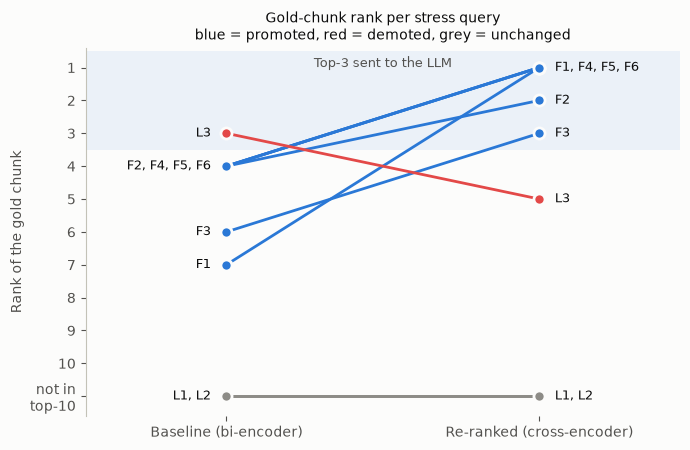

In [10]:
shift_df = pd.DataFrame([{k: r[k] for k in ["id", "category", "gold_baseline_rank", "gold_rerank_rank", "baseline_top3", "rerank_top3"]}
                         for r in failure_records])
shift_df["in_top3_baseline"] = shift_df.gold_baseline_rank.apply(lambda r: r is not None and r <= 3)
shift_df["in_top3_rerank"] = shift_df.gold_rerank_rank.apply(lambda r: r is not None and r <= 3)
shift_df.to_csv(RESULTS / "rank_shifts.csv", index=False)
display(shift_df)

# Slope chart: gold chunk rank before vs after re-ranking (rank 11 = "not in Top-10").
fig, ax = plt.subplots(figsize=(7, 4.6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.axhspan(0.5, 3.5, color="#2a78d6", alpha=0.08, lw=0)
ax.text(0.5, 0.65, "Top-3 sent to the LLM", ha="center", va="top", fontsize=9, color="#52514e")
rank_or_11 = lambda v: 11 if pd.isna(v) else int(v)          # 11 = "not in Top-10"
left, right = {}, {}
for _, r in shift_df.iterrows():
    b, a = rank_or_11(r.gold_baseline_rank), rank_or_11(r.gold_rerank_rank)
    color = "#2a78d6" if a < b else ("#e34948" if a > b else "#8d8c87")
    ax.plot([0, 1], [b, a], color=color, lw=2, marker="o", ms=8, mec="#fcfcfb", mew=2, zorder=3)
    left.setdefault(b, []).append(r.id); right.setdefault(a, []).append(r.id)
for y, ids in left.items():                                   # one combined label per rank, no overlaps
    ax.text(-0.05, y, ", ".join(ids), ha="right", va="center", fontsize=9, color="#0b0b0b")
for y, ids in right.items():
    ax.text(1.05, y, ", ".join(ids), ha="left", va="center", fontsize=9, color="#0b0b0b")
ax.set_xticks([0, 1], ["Baseline (bi-encoder)", "Re-ranked (cross-encoder)"])
ax.set_yticks(range(1, 12), [str(i) for i in range(1, 11)] + ["not in\ntop-10"])
ax.set_ylim(11.6, 0.4); ax.set_xlim(-0.45, 1.45)
ax.set_ylabel("Rank of the gold chunk", color="#52514e")
for s in ["top", "right", "bottom"]: ax.spines[s].set_visible(False)
ax.spines["left"].set_color("#c3c2b7"); ax.tick_params(colors="#52514e")
ax.set_title("Gold-chunk rank per stress query\nblue = promoted, red = demoted, grey = unchanged", fontsize=10, color="#0b0b0b")
plt.tight_layout(); plt.savefig(FIGS / "rank_shift.png", dpi=150); plt.show()

### 7.2 Answer 1 (baseline Top-3) vs Answer 2 (re-ranked Top-3)

Same prompt, same model, greedy decoding - only the context differs.

In [11]:
answer_records = []
for qid, cat, q, gold in FAILURE_QUERIES:
    top3_base, cands, _ = pipeline1(q)
    top3_rr, rows, _, _ = pipeline2(q, cands)
    a1, t1 = answer(q, top3_base)
    a2, t2 = answer(q, top3_rr)
    g = gold_ids(gold)
    rec = {"id": qid, "query": q,
           "context_1": [chunks[c]["source"] for c in top3_base], "gold_in_context_1": bool(g & set(top3_base)),
           "context_2": [chunks[c]["source"] for c in top3_rr], "gold_in_context_2": bool(g & set(top3_rr)),
           "answer_1": a1, "answer_2": a2, "gen_time_1": t1, "gen_time_2": t2}
    answer_records.append(rec)
    print(f"\n{'='*120}\n{qid} ({cat}) Q: {q}")
    print(f"\n--- Answer 1 | context {rec['context_1']} | gold in context: {rec['gold_in_context_1']}\n{a1}")
    print(f"\n--- Answer 2 | context {rec['context_2']} | gold in context: {rec['gold_in_context_2']}\n{a2}")

json.dump({"llm": llm.name, "records": answer_records, "rank_shifts": failure_records},
          open(RESULTS / "failure_answers.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)


F1 (Keyword trap / distractor) Q: How much can a company be fined for violating the conditions for consent?

--- Answer 1 | context ['Recital 150', 'Article 84', 'Article 83'] | gold in context: False
Answer: A company can be fined up to 2% of the total worldwide annual turnover of the preceding financial year, depending on the severity of the violation.

--- Answer 2 | context ['Article 83', 'Article 83', 'Article 83'] | gold in context: True
Answer: A company can be fined up to 20 million euros for violating the conditions for consent. This amount is determined by the severity of the violation and the gravity of the offense.



F2 (Exception / corner case) Q: When is a controller not required to tell individuals about a data breach?

--- Answer 1 | context ['Article 34', 'Recital 86', 'Recital 85'] | gold in context: False
Evidence: Recital 86

Answer: A controller is not required to inform individuals about a data breach if the personal data breach is likely to result in a high risk to the rights and freedoms of the natural person.

--- Answer 2 | context ['Recital 85', 'Article 34', 'Article 34'] | gold in context: True
Evidence: Recital 85, Cont.
Answer: A controller is not required to inform individuals about a data breach when:

1. The controller has already notified the supervisory authority within 72 hours.
2. The controller can demonstrate that the personal data breach is unlikely to result in a significant risk to the rights and freedoms of natural persons.
3. The controller takes appropriate technical and organisational protection measures to prevent the breach from occurring.
4. The controller tak


F3 (Negation & role limits) Q: Can a data protection officer be fired for doing their job?

--- Answer 1 | context ['Article 38', 'Article 37', 'Article 39'] | gold in context: False
Evidence: Article 38 states that a data protection officer can perform tasks related to personal data processing but cannot be fired for doing so.
Answer: A data protection officer cannot be fired for performing their job. According to Article 38, they are bound by secrecy or confidentiality regarding their tasks and cannot be fired for doing so.

--- Answer 2 | context ['Article 38', 'Article 37', 'Article 38'] | gold in context: True
Evidence: Article 38 states "The data protection officer shall be bound by secrecy or confidentiality concerning the performance of his or her tasks, in accordance with Union or Member State law." This implies that the data protection officer cannot be fired for doing their job.
Answer: No, a data protection officer cannot be fired for doing their job. According to Article 


F4 (Negation + synonym) Q: Is the controller allowed to ignore a request that is excessive?

--- Answer 1 | context ['Recital 64', 'Recital 63', 'Recital 47'] | gold in context: False
Answer: Evidence: Recital 64 states "The controller should use all reasonable measures to verify the identity of a data subject who requests access, in particular in the context of online services and online identifiers." This suggests that controllers have the responsibility to verify the identity of individuals requesting access to their data.
Answer: Recital 63 states "Where possible, the controller should be able to provide remote access to a secure system which would provide the data subject with direct access to his or her personal data." This indicates that controllers have the ability to provide remote access to data subjects.
Answer: Recital 47 states "The legitimate interests of a controller, including those of a controller to which the personal data may be disclosed, or of a third party, may p


F5 (Buried exception (rank 4-10)) Q: Is consent valid if the service is conditional on agreeing to unnecessary data processing?

--- Answer 1 | context ['Recital 43', 'Recital 32', 'Article 7'] | gold in context: False
Evidence: Recital 43 states "If the data subject's consent is to be given following a request by electronic means, the request must be clear, concise and not unnecessarily disruptive to the use of the service for which it is provided."

Answer: Yes, consent can be valid even if the service is conditional on agreeing to unnecessary data processing. The requirement for clarity, conciseness, and accessibility in the request for consent aligns with the principle of free consent, allowing for the separation of consent for different types of personal data processing while still ensuring that consent is freely given.

--- Answer 2 | context ['Article 7', 'Recital 43', 'Recital 32'] | gold in context: True
Evidence: 
The data subject shall have the right to withdraw his or her 


F6 (Scope exception (rank 4-10)) Q: Can government bodies be fined under the GDPR?

--- Answer 1 | context ['Article 83', 'Recital 154', 'Article 83'] | gold in context: False
Evidence: 
The reference to public authorities and bodies should in that context include all authorities or other bodies covered by Member State law on public access to documents. Directive 2003/98/EC of the European Parliament and of the Council (1) leaves intact and in no way affects the level of protection of natural persons with regard to the processing of personal data under the provisions of Union and Member State law, and in particular does not alter the obligations and rights set out in this Regulation.

Answer: Government bodies can be fined under the GDPR. According to Article 83 of the GDPR, government bodies can be fined if they intentionally or negligently, for the same or linked processing operations, infringe several provisions of this Regulation.

--- Answer 2 | context ['Article 83', 'Article 83


L1 (Limitation: recall ceiling) Q: When can a controller refuse a request to erase personal data?

--- Answer 1 | context ['Recital 66', 'Article 17', 'Article 17'] | gold in context: False
Evidence: Recital 66

Answer: A controller may refuse a request to erase personal data when it has made the personal data public and is obliged pursuant to paragraph 1 to erase the personal data. The controller must take reasonable steps, including technical measures, to inform controllers which are processing the personal data that the data subject has requested the erasure by such controllers of any links to, or copies or replications of, those personal data.
Evidence: Article 17

Answer: The controller must take reasonable steps, including technical measures, to inform controllers which are processing the personal data that the data subject has requested the erasure by such controllers of any links to, or copies or replications of, those personal data.

--- Answer 2 | context ['Article 17', 'Art


L2 (Limitation: vocabulary gap) Q: When must a company appoint a DPO?

--- Answer 1 | context ['Article 54', 'Article 62', 'Article 56'] | gold in context: False
Evidence: 
When the Company must appoint a DPO.

Answer: A company must appoint a Data Protection Officer (DPO) according to Article 54 of the General Data Protection Regulation (GDPR). This regulation requires companies to establish supervisory authorities, qualify their members, set rules and procedures for appointments, and have a term limit of up to four years. Additionally, companies are prohibited from seeking reimbursement from other Member States for damages related to data protection obligations.

--- Answer 2 | context ['Article 54', 'Recital 134', 'Recital 121'] | gold in context: False
Evidence: 
When appropriate, the supervisory authority should participate in joint operations with other supervisory authorities.
Answer: A company must appoint a Data Protection Officer (DPO) when appropriate, according to Article 


L3 (Limitation: re-ranker regression) Q: Can a supervisory authority check the work of a judge?

--- Answer 1 | context ['Recital 143', 'Recital 129', 'Article 55'] | gold in context: True
Evidence: Recital 143, Cont.
Answer: No, a supervisory authority cannot check the work of a judge without being bound by the provisions of Article 263 TFEU.

--- Answer 2 | context ['Recital 118', 'Article 78', 'Recital 143'] | gold in context: False
Evidence: Recital 118 states "The independence of supervisory authorities should not mean that the supervisory authorities cannot be subject to control or monitoring mechanisms regarding their financial expenditure or to judicial review."

Answer: No, a supervisory authority cannot check the work of a judge without being subject to control or monitoring mechanisms regarding their financial expenditure or to judicial review.

Evidence: Article 78 states "Where proceedings are brought against a decision of a supervisory authority which was preceded by an 

## 8. Quantitative evaluation on a labelled query set

The failure queries above were *selected*, so on their own they over-state the benefit. To get an unbiased picture, both pipelines are scored on **55 hand-labelled questions** written in plain user language (gold = the chunk(s) containing the answering clause). Metrics:

* **Hit@1 / Hit@3** - is a gold chunk at rank 1 / in the Top-3 that the LLM sees? (Hit@3 is what matters for the generated answer.)
* **MRR@10** - mean reciprocal rank of the first gold chunk inside the Top-10.
* **Recall@10** - is the gold chunk in the Top-10 at all? This is the *ceiling* for Pipeline 2: the re-ranker can only re-order what stage 1 found, so Recall@10 is identical for both pipelines.

In [12]:
EVAL_SET = [
    ("How long does a company have to report a data leak to the authorities?", ["not later than 72 hours after having become aware"]),
    ("What is the maximum fine for breaking the rules?", ["up to 20 000 000 EUR"]),
    ("At what age can a child consent to online services on their own?", ["at least 16 years"]),
    ("When can a controller refuse a request to erase personal data?", ["Paragraphs 1 and 2 shall not apply to the extent that processing is necessary"]),
    ("Does a company with fewer than 250 employees need to keep records of processing activities?", ["fewer than 250 persons"]),
    ("When is a controller not required to tell individuals about a data breach?", ["communication to the data subject referred to in paragraph 1 shall not be required"]),
    ("Is a company outside the EU always required to appoint a representative in the Union?", ["obligation laid down in paragraph 1 of this Article shall not apply"]),
    ("Which activities is the GDPR not applicable to?", ["This Regulation does not apply to the processing of personal data"]),
    ("Can a data protection officer be fired for doing their job?", ["shall not be dismissed or penalised"]),
    ("Is it prohibited to process health data?", ["Paragraph 1 shall not apply if one of the following applies"]),
    ("Can a person refuse to be subject to a decision made only by an algorithm?", ["shall have the right not to be subject to a decision based solely"]),
    ("Can the controller charge a fee for giving me a copy of my data?", ["For any further copies requested by the data subject"]),
    ("Can the supervisory authority charge the data subject for handling a complaint?", ["free of charge for the data subject"]),
    ("Is consent valid if the service is conditional on agreeing to unnecessary data processing?", ["performance of a contract, including the provision of a service, is conditional on consent"]),
    ("Can a member state lower the age of consent for children below 13?", ["not below 13 years"]),
    ("How quickly must a controller respond to a data subject's access request?", ["within one month of receipt of the request"]),
    ("When is a data protection impact assessment not required?", ["for which no data protection impact assessment is required", "Paragraphs 1 to 7 shall not apply"]),
    ("Can personal data about criminal convictions be processed by private companies?", ["shall be carried out only under the control of official authority"]),
    ("Does the right to data portability apply to processing for a public interest task?", ["shall not apply to processing necessary for the performance of a task carried out in the public interest"]),
    ("Can a processor hire another processor without telling the controller?", ["shall not engage another processor without prior specific or general written authorisation"]),
    ("Is a household address book kept by an individual covered by the regulation?", ["purely personal or household activity"]),
    ("Who must pay compensation when a processor causes damage?", ["shall be liable for the damage caused by processing only where it has not complied"]),
    ("Can data be transferred to a country without an adequacy decision?", ["In the absence of an adequacy decision pursuant to Article 45(3)"]),
    ("Does the regulation protect information about people who have died?", ["does not apply to the personal data of deceased persons"]),
    ("What penalties apply to a company that breaks the rules?", ["up to 20 000 000 EUR", "up to 10 000 000 EUR"]),
    ("How much can a company be fined for violating the conditions for consent?", ["Infringements of the following provisions shall, in accordance with paragraph 2, be subject to administrative fines up to 20 000 000 EUR"]),
    ("Can a company refuse to delete my data because it needs it for a lawsuit?", ["Paragraphs 1 and 2 shall not apply to the extent that processing is necessary"]),
    ("Is a company forbidden from processing data about someone's religion?", ["Processing of personal data revealing racial or ethnic origin, political opinions, religious"]),
    ("Can an employer process biometric data?", ["biometric data for the purpose of uniquely identifying"]),
    ("Does an organisation that only occasionally processes data outside the EU need a representative?", ["processing which is occasional"]),
    ("Is the controller allowed to ignore a request that is excessive?", ["the controller may either"]),
    ("Can a controller refuse to act on a request that is repetitive?", ["the controller may either"]),
    ("Who is not allowed to give instructions to the data protection officer?", ["does not receive any instructions regarding the exercise of those tasks"]),
    ("Are courts supervised by the data protection authority?", ["Supervisory authorities shall not be competent to supervise processing operations of courts"]),
    ("Can a supervisory authority check the work of a judge?", ["Supervisory authorities shall not be competent to supervise processing operations of courts"]),
    ("Can personal data be transferred abroad if the person explicitly agrees?", ["the data subject has explicitly consented to the proposed transfer"]),
    ("Can data be moved to a third country based on the individual's consent?", ["the data subject has explicitly consented to the proposed transfer"]),
    ("When does the controller not need to inform a person whose data was obtained from someone else?", ["Paragraphs 1 to 4 shall not apply where and insofar as"]),
    ("Is the controller exempt from informing the data subject when providing the information would be impossible?", ["the provision of such information proves impossible or would involve a disproportionate effort"]),
    ("Do small businesses need to appoint a data protection officer?", ["core activities of the controller or the processor consist of processing operations which"]),
    ("When must a company appoint a DPO?", ["core activities of the controller or the processor consist of processing operations which"]),
    ("Can someone withdraw their consent and is it as easy as giving it?", ["It shall be as easy to withdraw as to give consent"]),
    ("Does withdrawing consent make earlier processing illegal?", ["withdrawal of consent shall not affect the lawfulness of processing based on consent before its withdrawal"]),
    ("Can a public authority rely on legitimate interests as a legal basis?", ["shall not apply to processing carried out by public authorities in the performance of their tasks"]),
    ("What must a controller do if personal data is lost or stolen?", ["not later than 72 hours after having become aware"]),
    ("Can marketing emails be stopped by the person?", ["Where personal data are processed for direct marketing purposes, the data subject shall have the right to object"]),
    ("Can I object to direct marketing at any time?", ["Where personal data are processed for direct marketing purposes, the data subject shall have the right to object"]),
    ("What happens to the data after I object to direct marketing?", ["the personal data shall no longer be processed for such purposes"]),
    ("Is it necessary to notify the supervisory authority when a breach is unlikely to cause harm?", ["unless the personal data breach is unlikely to result in a risk"]),
    ("Can a processor be fined directly?", ["infringements of the following provisions shall, in accordance with paragraph 2, be subject to administrative fines"]),
    ("Are fines imposed on public authorities?", ["whether and to what extent administrative fines may be imposed on public authorities"]),
    ("Can government bodies be fined under the GDPR?", ["whether and to what extent administrative fines may be imposed on public authorities"]),
    ("Can a child's consent be used for offline services?", ["information society services directly to a child"]),
    ("Can a profiling decision be based on sensitive data like health?", ["shall not be based on special categories of personal data referred to in Article 9(1)"]),
    ("Is automated decision making allowed when it is needed for a contract?", ["is necessary for entering into, or performance of, a contract between the data subject and a data controller"]),
]
assert all(gold_ids(g) for _, g in EVAL_SET), "every query must have at least one gold chunk"
print(len(EVAL_SET), "labelled queries")

def first_gold_rank(ranked_ids, g):
    return next((r for r, cid in enumerate(ranked_ids, 1) if cid in g), None)

eval_rows = []
for q, gold in EVAL_SET:
    g = gold_ids(gold)
    cands, t_ret = dense_search(q)
    rows, t_rr = rerank(q, cands)
    rb = first_gold_rank([c for c, _ in cands], g)
    ra = first_gold_rank([r["chunk_id"] for r in rows], g)
    eval_rows.append({"query": q, "rank_baseline": rb, "rank_rerank": ra, "t_retrieval": t_ret, "t_rerank": t_rr,
                      "top_ce_score": rows[0]["ce_score"]})
ev = pd.DataFrame(eval_rows)

def metrics(col):
    r = ev[col]
    return {"Hit@1": (r == 1).mean(), "Hit@3": (r <= 3).mean(), "MRR@10": r.apply(lambda x: 1 / x if pd.notna(x) else 0).mean(),
            "Recall@10": r.notna().mean()}

metric_df = pd.DataFrame({"Pipeline 1 - Baseline": metrics("rank_baseline"), "Pipeline 2 - Re-ranked": metrics("rank_rerank")}).T.round(3)
display(metric_df)
metric_df.to_csv(RESULTS / "retrieval_metrics.csv")

moved = ev.dropna(subset=["rank_baseline"])
print(f"gold chunk promoted: {(moved.rank_rerank < moved.rank_baseline).sum()} | unchanged: {(moved.rank_rerank == moved.rank_baseline).sum()} "
      f"| demoted: {(moved.rank_rerank > moved.rank_baseline).sum()} | not retrieved in Top-10: {ev.rank_baseline.isna().sum()}")
print(f"entered the Top-3 thanks to re-ranking: {((ev.rank_baseline > 3) & (ev.rank_rerank <= 3)).sum()} | "
      f"pushed out of the Top-3 by re-ranking: {((ev.rank_baseline <= 3) & (ev.rank_rerank > 3)).sum()}")
ev.to_csv(RESULTS / "eval_per_query.csv", index=False)

55 labelled queries


,Hit@1,Hit@3,MRR@10,Recall@10
Pipeline 1 - Baseline,0.309,0.582,0.456,0.745
Pipeline 2 - Re-ranked,0.455,0.655,0.572,0.745


gold chunk promoted: 17 | unchanged: 19 | demoted: 5 | not retrieved in Top-10: 14
entered the Top-3 thanks to re-ranking: 6 | pushed out of the Top-3 by re-ranking: 2


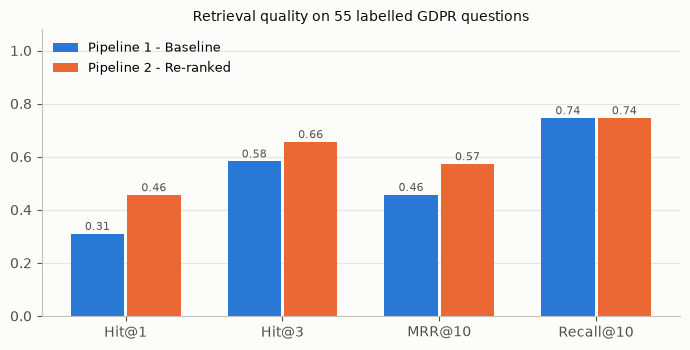

In [13]:
# Grouped bar chart of the four metrics.
fig, ax = plt.subplots(figsize=(7, 3.6), facecolor="#fcfcfb"); ax.set_facecolor("#fcfcfb")
x = np.arange(len(metric_df.columns)); w = 0.36
for i, (name, color) in enumerate(zip(metric_df.index, ["#2a78d6", "#eb6834"])):
    bars = ax.bar(x + (i - 0.5) * w, metric_df.loc[name], w - 0.02, color=color, label=name)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, metric_df.columns); ax.set_ylim(0, 1.08)
ax.legend(frameon=False, fontsize=9, loc="upper left")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.spines["left"].set_color("#c3c2b7"); ax.spines["bottom"].set_color("#c3c2b7"); ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_title(f"Retrieval quality on {len(ev)} labelled GDPR questions", fontsize=10, color="#0b0b0b")
plt.tight_layout(); plt.savefig(FIGS / "retrieval_metrics.png", dpi=150); plt.show()

## 9. Latency profiling

Each stage is timed with `time.perf_counter()` on CPU (Intel i5-13500, no GPU). Every query in the evaluation set is run **5 times** after a warm-up; the table reports per-query statistics in milliseconds. LLM time is measured from the generation runs in section 7.2 (it is the same for both pipelines apart from prompt length).

In [14]:
REPEATS = 5
lat = []
for q, _ in EVAL_SET:
    for _ in range(REPEATS):
        cands, t_ret = dense_search(q)
        _, t_rr = rerank(q, cands)
        lat.append({"Stage 1: bi-encoder retrieval (query encode + top-10 search)": t_ret * 1000,
                    "Stage 2: cross-encoder re-rank of 10 pairs": t_rr * 1000,
                    "Pipeline 1 total retrieval": t_ret * 1000,
                    "Pipeline 2 total retrieval": (t_ret + t_rr) * 1000})
lat_df = pd.DataFrame(lat)
gen_ms = [r["gen_time_1"] * 1000 for r in answer_records] + [r["gen_time_2"] * 1000 for r in answer_records]
lat_df["LLM generation (per answer)"] = pd.Series(gen_ms)
lat_table = lat_df.agg(["mean", "median", lambda s: s.quantile(0.95)]).T
lat_table.columns = ["mean (ms)", "median (ms)", "p95 (ms)"]
lat_table = lat_table.round(1)
display(lat_table)
lat_table.to_csv(RESULTS / "latency.csv")

p1, p2 = lat_table.loc["Pipeline 1 total retrieval", "mean (ms)"], lat_table.loc["Pipeline 2 total retrieval", "mean (ms)"]
g = lat_table.loc["LLM generation (per answer)", "mean (ms)"]
print(f"Re-ranking makes retrieval {p2/p1:.1f}x slower (+{p2-p1:.0f} ms), "
      f"but end-to-end only {(p2+g)/(p1+g):.3f}x slower because generation takes ~{g/1000:.1f} s.")
print(f"One-off indexing cost (offline): {index_time*1000:.0f} ms for {len(chunks)} chunks")

,mean (ms),median (ms),p95 (ms)
Stage 1: bi-encoder retrieval (query encode + top-10 search),22.7,22.8,26.8
Stage 2: cross-encoder re-rank of 10 pairs,215.3,209.9,272.7
Pipeline 1 total retrieval,22.7,22.8,26.8
Pipeline 2 total retrieval,238.1,232.4,297.6
LLM generation (per answer),12336.9,11952.2,18689.3


Re-ranking makes retrieval 10.5x slower (+215 ms), but end-to-end only 1.017x slower because generation takes ~12.3 s.
One-off indexing cost (offline): 7664 ms for 523 chunks


## 10. Scaling experiment - why not run the cross-encoder over the whole corpus?

Two measurements support the scaling answer in the report:

1. **Cost:** time to score *one* query against *all* 523 chunks with the cross-encoder vs. the bi-encoder search.
2. **Benefit:** retrieval quality when the cross-encoder ranks the whole corpus, compared with re-ranking only the Top-10 / Top-20 / Top-50 bi-encoder candidates.

In [15]:
all_texts = [c["text"] for c in chunks]
q = "Can a data protection officer be fired for doing their job?"
t0 = time.perf_counter(); full_scores = cross_encoder.predict([(q, t) for t in all_texts], batch_size=64, show_progress_bar=False)
t_full = time.perf_counter() - t0
t0 = time.perf_counter(); dense_search(q, k=len(chunks)); t_dense = time.perf_counter() - t0
per_pair_ms = t_full * 1000 / len(chunks)
print(f"cross-encoder over ALL {len(chunks)} chunks: {t_full*1000:.0f} ms ({per_pair_ms:.2f} ms per pair)")
print(f"bi-encoder over ALL {len(chunks)} chunks:    {t_dense*1000:.1f} ms (chunk vectors precomputed)")
for n in [10_000, 1_000_000, 100_000_000]:
    print(f"  extrapolated cross-encoder cost for {n:>11,} chunks: {per_pair_ms*n/1000/60:>10,.1f} min per query")

cross-encoder over ALL 523 chunks: 8727 ms (16.69 ms per pair)
bi-encoder over ALL 523 chunks:    21.8 ms (chunk vectors precomputed)
  extrapolated cross-encoder cost for      10,000 chunks:        2.8 min per query
  extrapolated cross-encoder cost for   1,000,000 chunks:      278.1 min per query
  extrapolated cross-encoder cost for 100,000,000 chunks:   27,809.8 min per query


In [16]:
# Re-ranking depth vs quality vs latency, plus the "cross-encoder over everything" upper bound.
depth_rows = []
for depth in [10, 20, 50, len(chunks)]:
    hits3, mrr, times = [], [], []
    for qq, gold in EVAL_SET:
        g = gold_ids(gold)
        t0 = time.perf_counter()
        if depth == len(chunks):
            s = cross_encoder.predict([(qq, t) for t in all_texts], batch_size=64, show_progress_bar=False)
            ranked = list(np.argsort(-s))
        else:
            cands, _ = dense_search(qq, k=depth)
            rows, _ = rerank(qq, cands)
            ranked = [r["chunk_id"] for r in rows]
        times.append(time.perf_counter() - t0)
        r = first_gold_rank(ranked, g)
        hits3.append(r is not None and r <= 3); mrr.append(1 / r if r and r <= 10 else 0)
    depth_rows.append({"candidates re-ranked": "all (no stage 1)" if depth == len(chunks) else depth,
                       "Hit@3": np.mean(hits3), "MRR@10": np.mean(mrr), "mean latency (ms)": np.mean(times) * 1000})
depth_df = pd.DataFrame(depth_rows).round(3)
display(depth_df)
depth_df.to_csv(RESULTS / "rerank_depth.csv", index=False)

,candidates re-ranked,Hit@3,MRR@10,mean latency (ms)
0,10,0.655,0.572,240.525
1,20,0.691,0.592,426.635
2,50,0.764,0.624,953.912
3,all (no stage 1),0.764,0.634,8707.354


## 11. Summary

* The results tables and figures above are saved in `results/` and `figures/`.
* The written analysis (architecture, rank shifts, answer comparison, latency, scaling) is in `REPORT.md`.